# Cluster

> Es un modulo para hacer clusters espaciales 

In [ ]:
#| default_exp cluster_ejemplo

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| hide
#| export 
import matplotlib
import sklearn
import random
import numpy as np
import shapely
from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, KMeans
import matplotlib.pyplot as plt

In [ ]:
#| export

class data_points:
    """Una clase que contiene a los datos"""
    def __init__(self,
                 n,
                 min_x = 0,
                 min_y = 0,
                 max_x= 1,
                 max_y=1,
                 seed= None):
        
        if seed != None:
            random.seed(seed)
        
        x_val = np.random.uniform(low= min_x, high= max_x, size=(n, 1));
        y_val = np.random.uniform(low= min_y, high= max_y, size=(n, 1));
        self.Points =  [shapely.Point(x[0],x[1]) for x in zip(x_val, y_val)]
    def get_points(self):
        """Una funcion que para obtener los puntos"""
        return self.Points

    def get_Multypoint(self):
        """Regresa un objeto MultiPoint con los puntos"""
        return shapely.geometry.MultiPoint(self.Points)
    
    def get_X(self):
        """Regresa las coordenadas X"""
        return [x.x for x in self.Points]

    def get_Y(self):
        """Regresa las coordenadas Y"""
        return [x.y for x in self.Points]

    def centroid(self):
        """Regresa el centroide de los puntos """
        return shapely.centroid(self.get_Multypoint())

    def as_array(self):
        """Regresa los puntos como un array"""
        list_arrays = np.array([(geom.xy[0][0], geom.xy[1][0]) for geom in self.Points])
        return list_arrays

    def add_points(self, data_points):
        """Agrega puntos de otra """
        self.Points = self.Points + data_points.Points
        return

In [ ]:
#| hide
clase_puntos = data_points(500)
clase_puntos.Points

[<POINT (0.86 0.234)>,
 <POINT (0.282 0.342)>,
 <POINT (0.491 0.077)>,
 <POINT (0.577 0.9)>,
 <POINT (0.736 0.623)>,
 <POINT (0.804 0.703)>,
 <POINT (0.069 0.278)>,
 <POINT (0.839 0.895)>,
 <POINT (0.389 0.157)>,
 <POINT (0.172 0.094)>,
 <POINT (0.672 0.751)>,
 <POINT (0.141 0.662)>,
 <POINT (0.251 0.618)>,
 <POINT (0.195 0.325)>,
 <POINT (0.022 0.297)>,
 <POINT (0.646 0.527)>,
 <POINT (0.183 0.596)>,
 <POINT (0.623 0.4)>,
 <POINT (0.112 0.142)>,
 <POINT (0.145 0.133)>,
 <POINT (0.353 0.272)>,
 <POINT (0.6 0.685)>,
 <POINT (0.592 0.389)>,
 <POINT (0.254 0.085)>,
 <POINT (0.398 0.114)>,
 <POINT (0.208 0.775)>,
 <POINT (0.993 0.108)>,
 <POINT (0.603 0.895)>,
 <POINT (0.657 0.703)>,
 <POINT (0.511 0.391)>,
 <POINT (0.091 0.416)>,
 <POINT (0.767 0.919)>,
 <POINT (0.639 0.271)>,
 <POINT (0.081 0.37)>,
 <POINT (0.938 0.196)>,
 <POINT (0.276 0.381)>,
 <POINT (0.686 0.754)>,
 <POINT (0.932 0.841)>,
 <POINT (0.332 0.007)>,
 <POINT (0.139 0.345)>,
 <POINT (0.934 0.364)>,
 <POINT (0.941 0.426)>,


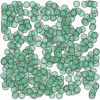

In [ ]:
clase_puntos.get_Multypoint()    
    

In [ ]:
#| hide 
puntos_simples = data_points(n= 500)

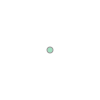

In [ ]:
#| hide
puntos_simples.centroid()

In [ ]:
#| hide
puntos_simples.get_points()

[<POINT (0.368 0.854)>,
 <POINT (0.854 0.163)>,
 <POINT (0.743 0.219)>,
 <POINT (0.411 0.914)>,
 <POINT (0.687 0.113)>,
 <POINT (0.168 0.74)>,
 <POINT (0.983 0.991)>,
 <POINT (0.521 0.453)>,
 <POINT (0.833 0.603)>,
 <POINT (0.381 0.238)>,
 <POINT (0.633 0.129)>,
 <POINT (0.148 0.563)>,
 <POINT (0.699 0.941)>,
 <POINT (0.864 0.038)>,
 <POINT (0.789 0.284)>,
 <POINT (0.553 0.846)>,
 <POINT (0.72 0.785)>,
 <POINT (0.57 0.607)>,
 <POINT (0.857 0.853)>,
 <POINT (0.108 0.132)>,
 <POINT (0.254 0.515)>,
 <POINT (0.182 0.097)>,
 <POINT (0.025 0.723)>,
 <POINT (0.13 0.904)>,
 <POINT (0.049 0.638)>,
 <POINT (0.936 0.568)>,
 <POINT (0.13 0.537)>,
 <POINT (0.348 0.198)>,
 <POINT (0.947 0.427)>,
 <POINT (0.933 0.287)>,
 <POINT (0.933 0.063)>,
 <POINT (0.889 0.38)>,
 <POINT (0.536 0.727)>,
 <POINT (0.516 0.272)>,
 <POINT (0.092 0.811)>,
 <POINT (0.587 0.275)>,
 <POINT (0.328 0.294)>,
 <POINT (0.935 0.971)>,
 <POINT (0.189 0.031)>,
 <POINT (0.074 0.013)>,
 <POINT (0.457 0.681)>,
 <POINT (0.116 0.116)>

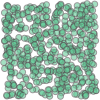

In [ ]:
#| hide
puntos_simples.get_Multypoint()

In [ ]:
#| hide
puntos_simples.get_X()

[0.36791311840468033,
 0.8535416587502889,
 0.7427084148645093,
 0.4111909197231286,
 0.686532187108859,
 0.16847433305353832,
 0.9832544919858216,
 0.5209846768135777,
 0.8334383435768266,
 0.38076958687369866,
 0.6327600970454462,
 0.14835259911747756,
 0.6989007979203804,
 0.864451447178217,
 0.7889526892930049,
 0.5529524431804226,
 0.7197942344953878,
 0.5698036519350946,
 0.8566094748380129,
 0.10818003229837936,
 0.2542632790795455,
 0.1824973678328362,
 0.024513942104934294,
 0.13044303482646424,
 0.04883121126828183,
 0.9357941970346595,
 0.13012629527526676,
 0.3477757827996548,
 0.9468654133907526,
 0.9329254171492151,
 0.9329487247496974,
 0.8893144600484408,
 0.536373573080176,
 0.5161282419756276,
 0.09201062913275238,
 0.5868984988117915,
 0.3278911589034237,
 0.9353020962486551,
 0.18943337441564778,
 0.07363614580803712,
 0.4574679447864288,
 0.11615921397049123,
 0.9195244400504793,
 0.2449552899184564,
 0.262231941040166,
 0.4774408465357932,
 0.3728808494401519,
 0.

In [ ]:
#| hide
puntos_simples.get_Y()

[0.8542704093747626,
 0.1630903131599567,
 0.21942816634254914,
 0.9141673317544989,
 0.11260538236624784,
 0.740138972880157,
 0.990579226815585,
 0.45316538364336545,
 0.6027605911295784,
 0.23825951617179442,
 0.1292356469998438,
 0.5633864267746713,
 0.9414998590136531,
 0.03826805142397538,
 0.28434081182947524,
 0.8456126070007146,
 0.7851509858306478,
 0.6066060167072099,
 0.8526598708453494,
 0.13218033875071333,
 0.5154414383154129,
 0.09729903146329677,
 0.7231484795534588,
 0.9037079727534717,
 0.6381019425868681,
 0.5675642702323277,
 0.5371412981547258,
 0.1976033361765689,
 0.4268107240547,
 0.2872959326624064,
 0.06296595426517337,
 0.38004645529330017,
 0.7267074337874578,
 0.27155785644206787,
 0.8114903155722524,
 0.275086552940352,
 0.2943466576630923,
 0.9713826795859556,
 0.030861276681080296,
 0.013288339819857997,
 0.6810709275875336,
 0.11609800875777043,
 0.4195783400720793,
 0.20332099032312012,
 0.6193287263498489,
 0.3709795666362996,
 0.3194523648708353,
 0

In [ ]:
#| hide 
if len(puntos_simples.get_X()) != len(puntos_simples.get_Y()):
    raise Exception("Si hay problema la evaluacion ")

## Clusters

A partir de la clase data_point podemos generar muchos puntos y queremos hacer un agrupamiento de dichos puntos 


In [ ]:
#| export 
class Clusters:
  """
  Clase para generar los clusters a partir de un objeto de la clase data_points
  
  Esta clase se utiliza para generar los distintos tipos de clusterizaciones, 
  se almacena los datos en una estructura de datos y se le añaden las respectivas 
  classes
  """
    
  def __init__(self, data_points_i, seed=1234):
    if seed != None:
      random.seed(seed)
      self.data_structure =  data_points_i
    
  def KMeans(self, **kwargs):
    """
    Se usa el algoritmo Kmeans para la obtencion de clusters, 
    las clases quedan almacenadas en .data_structure_classes_Kmeans.
    Si se desea obtener el modelo se tiene que añadir 
    (ret_model = True) como parámetro.
    """
    kmeans_c = KMeans(**kwargs)
    classes_val = kmeans_c.fit_predict(self.data_structure.as_array())
    self.data_structure.classes_Kmeans = classes_val
    
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  kmeans_c
        

  def DBSCAN(self, **kwargs):
    """
    Se DBSCAN para la obtencion de clusters, las clases quedan almacenadas
    en .data_structure_classes_DBSCAN. Si se desea obtener el modelo se tiene
    que añadir (ret_model = True) como parámetro.
    """
    db = DBSCAN(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_DBSCAN = db.labels_
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  db
    
    
  def HDBSCAN(self, **kwargs):
    """
    Se HDBSCAN para la obtencion de clusters, las clases quedan almacenadas
    en .data_structure_classes_HDBSCAN. Si se desea obtener el modelo se tiene
    que añadir (ret_model = True) como parámetro.
    """
    hdb = HDBSCAN(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_HDBSCAN = hdb.labels_
    if 'ret_model' in kwargs and kwargs['ret_model']==True : 
      return  hdb
        

  def OPTICS(self, **kwargs):
    """
    Se usa el algoritmo OPTICS para la obtencion de clusters, 
    las clases quedan almacenadas en .data_structure_classes_OPTICS.
    Si se desea obtener el modelo se tiene que añadir 
    (ret_model = True) como parámetro.
    """
    optics=  OPTICS(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_OPTICS = optics.labels_
    
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  optics

In [ ]:
show_doc(Clusters.DBSCAN)

---

### Clusters.DBSCAN

```python
def DBSCAN(
    **kwargs
):
```

*Se DBSCAN para la obtencion de clusters, las clases quedan almacenadas*
en .data_structure_classes_DBSCAN. Si se desea obtener el modelo se tiene
que añadir (ret_model = True) como parámetro.

In [ ]:
show_doc(Clusters.KMeans)

---

### Clusters.KMeans

```python
def KMeans(
    **kwargs
):
```

*Se usa el algoritmo Kmeans para la obtencion de clusters, *
las clases quedan almacenadas en .data_structure_classes_Kmeans.
Si se desea obtener el modelo se tiene que añadir 
(ret_model = True) como parámetro.

In [ ]:
show_doc(Clusters.HDBSCAN)

---

### Clusters.HDBSCAN

```python
def HDBSCAN(
    **kwargs
):
```

*Se HDBSCAN para la obtencion de clusters, las clases quedan almacenadas*
en .data_structure_classes_HDBSCAN. Si se desea obtener el modelo se tiene
que añadir (ret_model = True) como parámetro.

In [ ]:
show_doc(Clusters.OPTICS)

---

### Clusters.OPTICS

```python
def OPTICS(
    **kwargs
):
```

*Se usa el algoritmo OPTICS para la obtencion de clusters, *
las clases quedan almacenadas en .data_structure_classes_OPTICS.
Si se desea obtener el modelo se tiene que añadir 
(ret_model = True) como parámetro.

In [ ]:
datos_simples_3 = data_points(500, min_x = 0.6, min_y= 0.6, max_x= 1.0, max_y= 1.0 )
datos_simples_2 = data_points(500, min_x = 0.0, min_y= 0.6, max_x= 0.4, max_y= 1.0 )

In [ ]:
datos_simples_1 = data_points(500, min_x = 0.6, min_y= 0.0, max_x= 1.0, max_y= 0.4 )
datos_simples_0 = data_points(500, min_x = 0.0, min_y= 0.0, max_x= 0.4, max_y= 0.4 )
datos_simples_0.add_points(datos_simples_1)

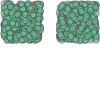

In [ ]:
datos_simples_0.get_Multypoint()

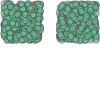

In [ ]:
datos_simples_0.get_Multypoint()

In [ ]:
datos_simples_0.add_points(datos_simples_1)
datos_simples_0.add_points(datos_simples_2)
datos_simples_0.add_points(datos_simples_3)

Vamos a utilizar nuestra clase clusters para ver como los distintos algoritmos hacen una clusterización 

In [ ]:
cluster_all  = Clusters(datos_simples_0)

In [ ]:
cluster_all.OPTICS()

In [ ]:
cluster_all.HDBSCAN()

/home/miguel/conda_previus/envs/nbdev_2026_t/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [ ]:
cluster_all.DBSCAN(eps=0.1, min_samples=10)

In [ ]:
cluster_all.KMeans()

# Kmeans

<matplotlib.collections.PathCollection>

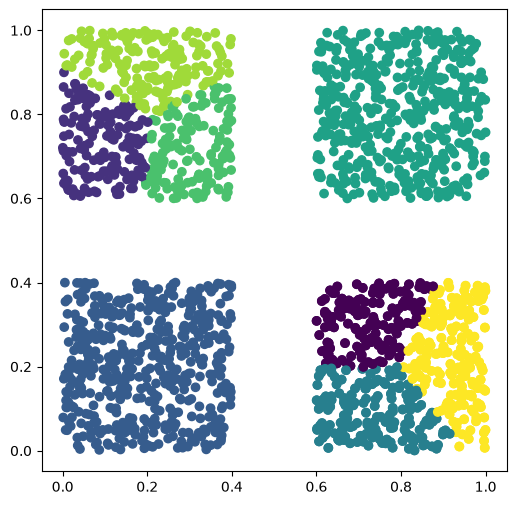

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

plt.scatter(
cluster_all.data_structure.get_X(),
cluster_all.data_structure.get_Y(),
c=cluster_all.data_structure.classes_Kmeans
)

Veamos en cuantas clases se agruparon

In [ ]:
np.unique(cluster_all.data_structure.classes_Kmeans)

array([0, 1, 2, 3, 4, 5, 6, 7], dtype=int32)

In [ ]:
np.unique(cluster_all.data_structure.classes_DBSCAN)

array([0, 1, 2, 3])

In [ ]:
np.unique(cluster_all.data_structure.classes_OPTICS)

array([ -1,   0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,
        12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,
        25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,
        38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,
        51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,
        64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,
        77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,
        90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
       103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115,
       116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128,
       129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141,
       142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154,
       155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167,
       168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 17

In [ ]:
np.unique(cluster_all.data_structure.classes_HDBSCAN)

array([0, 1, 2, 3])

# HDBSCAN

<matplotlib.collections.PathCollection>

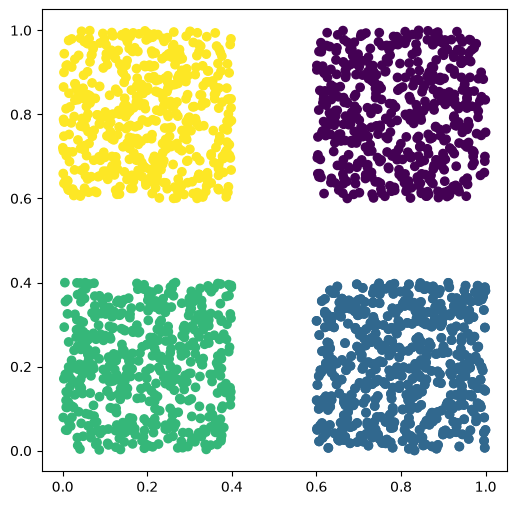

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

plt.scatter(
cluster_all.data_structure.get_X(),
cluster_all.data_structure.get_Y(),
c=cluster_all.data_structure.classes_HDBSCAN
)

# OPTICS

<matplotlib.collections.PathCollection>

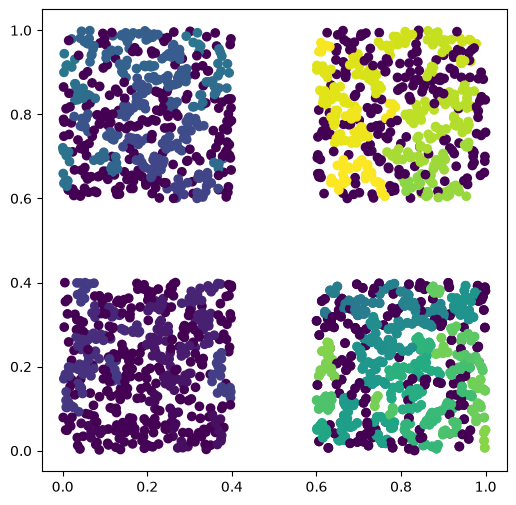

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

plt.scatter(
cluster_all.data_structure.get_X(),
cluster_all.data_structure.get_Y(),
c=cluster_all.data_structure.classes_OPTICS
)

<matplotlib.collections.PathCollection>

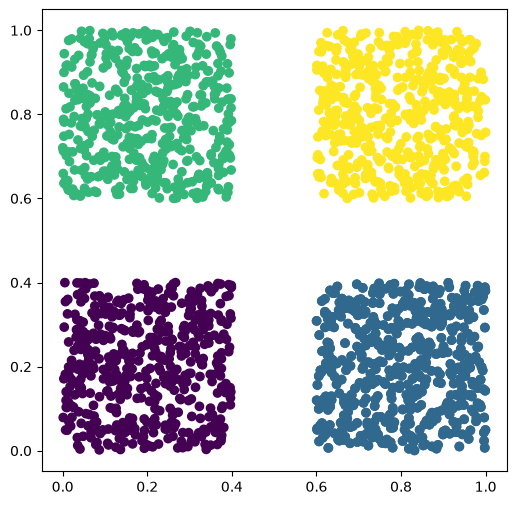

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

plt.scatter(
cluster_all.data_structure.get_X(),
cluster_all.data_structure.get_Y(),
c=cluster_all.data_structure.classes_DBSCAN
)

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()